# 🚀 Phase 1 Custom Projects Guide: Build Your Own Foundations Portfolio (4 Blueprints & Roadmaps)

---

## 1. Overview — From Learning Foundations to Shipping Your Own Systems

Reading notebooks builds understanding, but **building an unguided custom project** is what turns foundational math and Python knowledge into durable engineering skill. This notebook gives you **4 carefully scoped, interview-ready custom project blueprints** designed exclusively around **Phase 1 tools** (`Linear Algebra`, `Calculus`, `Probability/Stats`, `Python Mastery`, `NumPy`, `Pandas`, and `Git/Dev Tools`), complete with:

- **Step-by-step 5-milestone execution roadmaps** for each project
- **Working starter code prototypes** you can immediately expand into full GitHub repositories
- **An interactive Project Planner & Portfolio Rubric Evaluator** calibrated to this repository's official evaluation rubric

> **Rule of Thumb:** Pick **one** of the 4 blueprints below (or combine ideas into your own domain), clone a clean Git branch, follow the 5-milestone roadmap, and score at least **85/100** on the rubric before advancing to Phase 2.


## 2. Learning Objectives & Custom Project Selection Matrix

| # | Project Blueprint | Difficulty | Est. Time | Primary Phase 1 Notebooks Applied | Core Portfolio Deliverable |
|:-:|:---|:---:|:---:|:---|---|
| **1** | **`MicroGrad-Matrix`** — Vectorized Autodiff & Linear Algebra Engine | 🟡 Intermediate | 10–14h | `01` Linear Algebra, `02` Calculus, `04` Python OOP, `05` NumPy, `07` Git/Pytest | Reverse-mode matrix autograd engine + finite-diff test suite |
| **2** | **`AsyncPulse`** — Async Telemetry ETL & Bayesian Change-Point Alerter | 🟢–🟡 Practical | 8–12h | `03` Probability, `04` `asyncio`/Generators, `06` Pandas, `07` CLI | Concurrent data collector + Bayesian Poisson/Gaussian alert engine |
| **3** | **`LatentSearch`** — Pure-NumPy SVD & Cosine Similarity Search Engine | 🟢–🟡 Practical | 6–10h | `01` SVD/Eigen, `05` NumPy Vectorization, `06` Pandas Indexing | Truncated-SVD semantic search library over custom text corpora |
| **4** | **`DataGuard-CLI`** — Statistical Drift & Git Reproducibility Gate | 🟢 Beginner+ | 6–8h | `03` Stats/Distributions, `04` Dataclasses, `06` Pandas, `07` Git Hooks | Pre-commit CLI auditing schema, drift, and SHA-256 dataset hashes |


## 3. Imports & Environment Verification


In [1]:
import asyncio
import concurrent.futures
import hashlib
import math
import re
import sys
from dataclasses import dataclass, field
from typing import Any, Callable, Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

print("=== Phase 1 Custom Projects Workbench ===")
print(f"Python: {sys.version.split()[0]} | NumPy: {np.__version__} | Pandas: {pd.__version__}")


=== Phase 1 Custom Projects Workbench ===
Python: 3.14.10 | NumPy: 2.3.5 | Pandas: 2.3.3


## 4. Deterministic Configuration


In [2]:
SEED: int = 42
RNG: np.random.Generator = np.random.default_rng(SEED)

plt.rcParams["figure.figsize"] = (13, 6)
plt.rcParams["font.size"] = 10
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.rcParams["axes.grid"] = True

print(f"Workbench configured with deterministic seed = {SEED}")


Workbench configured with deterministic seed = 42


## 5. The 4 Custom Project Blueprints & Step-by-Step Roadmaps

---

### Blueprint 1: `MicroGrad-Matrix` — Vectorized Autodiff & Linear Algebra Engine From Scratch

**Why build it?** Every PyTorch/JAX model relies on reverse-mode automatic differentiation over matrix computation graphs. Implementing a matrix-level autograd engine using only NumPy makes backpropagation effortless to debug forever.

#### 5-Milestone Implementation Roadmap
1. **Milestone 1 (Graph Node & Shape Contract):** Wrap `np.ndarray` in a `Tensor` dataclass storing `.data`, `.grad`, `._prev` parent pointers, and `._backward` closure.
2. **Milestone 2 (Forward Primitives):** Implement `+`, `*`, `@` (`matmul`), `relu()`, and `mean()` with proper NumPy broadcasting support.
3. **Milestone 3 (Topological Reverse-Mode Autodiff):** Build a depth-first topological sort and propagate $\frac{\partial \mathcal{L}}{\partial X}$ backward using the chain rule (summing broadcasted axes).
4. **Milestone 4 (Finite-Difference Gradient Gate):** Write `pytest` tests comparing analytical `.grad` against central numerical differences ($\|\Delta\|_\infty < 10^{-6}$).
5. **Milestone 5 (Benchmark):** Train a 2-layer MLP on a non-linear spiral or XOR dataset using only your engine and plot the loss curve.

#### Starter Prototype (Run & Extend!)


In [3]:
class MatrixTensor:
    """Minimal reverse-mode autograd node over NumPy matrices (Blueprint 1 Starter)."""

    def __init__(self, data: np.ndarray, _children: Tuple["MatrixTensor", ...] = (), _op: str = "") -> None:
        self.data = np.asarray(data, dtype=np.float64)
        self.grad = np.zeros_like(self.data)
        self._backward: Callable[[], None] = lambda: None
        self._prev = set(_children)
        self._op = _op

    def __matmul__(self, other: "MatrixTensor") -> "MatrixTensor":
        out = MatrixTensor(self.data @ other.data, (self, other), "@")

        def _backward() -> None:
            self.grad += out.grad @ other.data.T
            other.grad += self.data.T @ out.grad

        out._backward = _backward
        return out

    def relu(self) -> "MatrixTensor":
        out = MatrixTensor(np.maximum(0.0, self.data), (self,), "relu")

        def _backward() -> None:
            self.grad += (self.data > 0.0) * out.grad

        out._backward = _backward
        return out

    def sum_squares(self) -> "MatrixTensor":
        out = MatrixTensor(np.array(np.sum(self.data ** 2)), (self,), "sum_sq")

        def _backward() -> None:
            self.grad += 2.0 * self.data * out.grad

        out._backward = _backward
        return out

    def backward(self) -> None:
        topo: List[MatrixTensor] = []
        visited = set()

        def build_topo(v: MatrixTensor) -> None:
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)
        self.grad = np.ones_like(self.data)
        for node in reversed(topo):
            node._backward()


# Quick verification of Blueprint 1 Starter: f(X, W) = sum((ReLU(X @ W))^2)
X_t = MatrixTensor([[1.2, -0.5], [0.3, 0.8]])
W_t = MatrixTensor([[0.7, -0.2], [0.4, 0.9]])
loss_t = (X_t @ W_t).relu().sum_squares()
loss_t.backward()

# Finite-difference check on W_t[0, 0]
eps = 1e-6
W_plus = W_t.data.copy(); W_plus[0, 0] += eps
W_minus = W_t.data.copy(); W_minus[0, 0] -= eps
num_grad_00 = (np.sum(np.maximum(0, X_t.data @ W_plus)**2) - np.sum(np.maximum(0, X_t.data @ W_minus)**2)) / (2 * eps)
print(f"[Blueprint 1] Loss={float(loss_t.data):.4f} | Analytic dL/dW[0,0]={W_t.grad[0,0]:.6f} | Numeric={num_grad_00:.6f}")


[Blueprint 1] Loss=1.1261 | Analytic dL/dW[0,0]=1.854000 | Numeric=1.854000


---

### Blueprint 2: `AsyncPulse` — Async Telemetry ETL & Bayesian Change-Point Alerter

**Why build it?** Modern AI systems ingest asynchronous streams (API latency, token throughput, error counts) and must separate real incidents from noisy spikes using Bayesian inference.

#### 5-Milestone Implementation Roadmap
1. **Milestone 1 (Async Producer/Consumer):** Build `asyncio.Queue` workers polling simulated or local HTTP/log feeds concurrently.
2. **Milestone 2 (Pandas Rolling ETL):** Aggregate raw events into fixed 1-minute buckets and compute rolling medians/IQRs.
3. **Milestone 3 (Gamma-Poisson Conjugate Model):** Model event counts $k \sim \text{Poisson}(\lambda)$ with a $\text{Gamma}(\alpha, \beta)$ prior updated sequentially.
4. **Milestone 4 (Alert Hysteresis):** Trigger alerts only when the posterior exceedance probability $P(\lambda > \lambda_{\text{threshold}} \mid \text{data}) > 0.95$.
5. **Milestone 5 (CLI Dashboard):** Export structured JSON alert logs and unit tests covering burst edge cases.

#### Starter Prototype (Run & Extend!)


In [4]:
async def collect_metrics_stream(n_windows: int = 8) -> List[int]:
    """Simulate async collection of per-minute error counts with a regime shift at t=5."""
    await asyncio.sleep(0.005)
    stream_rng = np.random.default_rng(SEED + 7)
    normal = stream_rng.poisson(lam=2.0, size=5).tolist()
    spike = stream_rng.poisson(lam=9.5, size=n_windows - 5).tolist()
    return normal + spike


def run_coro(coro: Any) -> Any:
    try:
        asyncio.get_running_loop()
        with concurrent.futures.ThreadPoolExecutor(max_workers=1) as pool:
            return pool.submit(asyncio.run, coro).result()
    except RuntimeError:
        return asyncio.run(coro)


counts = run_coro(collect_metrics_stream(8))
alpha, beta = 2.0, 1.0  # Gamma prior (mean = 2.0 errors/min)
threshold_rate = 4.5
print("[Blueprint 2] Sequential Gamma-Poisson Posterior Alerting:")
for t, k in enumerate(counts):
    alpha += k
    beta += 1.0
    post_mean = alpha / beta
    # P(lambda > threshold_rate) via survival function of Gamma(shape=alpha, scale=1/beta)
    p_alert = float(stats.gamma.sf(threshold_rate, a=alpha, scale=1.0 / beta))
    status = "ALERT" if p_alert > 0.95 else "OK"
    print(f"  t={t} | observed_errors={k:2d} | posterior_rate={post_mean:.2f} | P(rate>{threshold_rate})={p_alert:.3f} [{status}]")


[Blueprint 2] Sequential Gamma-Poisson Posterior Alerting:
  t=0 | observed_errors= 2 | posterior_rate=2.00 | P(rate>4.5)=0.021 [OK]
  t=1 | observed_errors= 2 | posterior_rate=2.00 | P(rate>4.5)=0.008 [OK]
  t=2 | observed_errors= 3 | posterior_rate=2.25 | P(rate>4.5)=0.007 [OK]
  t=3 | observed_errors= 5 | posterior_rate=2.80 | P(rate>4.5)=0.022 [OK]
  t=4 | observed_errors= 0 | posterior_rate=2.33 | P(rate>4.5)=0.002 [OK]
  t=5 | observed_errors= 5 | posterior_rate=2.71 | P(rate>4.5)=0.007 [OK]
  t=6 | observed_errors= 9 | posterior_rate=3.50 | P(rate>4.5)=0.074 [OK]
  t=7 | observed_errors=12 | posterior_rate=4.44 | P(rate>4.5)=0.448 [OK]


---

### Blueprint 3: `LatentSearch` — Pure-NumPy SVD & Cosine Similarity Semantic Search Engine

**Why build it?** Before reaching for heavy vector databases in Phase 4, understanding how matrix factorization (Truncated SVD / Latent Semantic Analysis) and normalized dot products retrieve documents in milliseconds gives you total intuition over embeddings.

#### 5-Milestone Implementation Roadmap
1. **Milestone 1 (Tokenizer & Vocabulary Builder):** Clean text, build vocabulary index, and compute a vectorized TF-IDF matrix in NumPy.
2. **Milestone 2 (Truncated SVD Compression):** Decompose the TF-IDF matrix via `np.linalg.svd` and project documents into a $k$-dimensional latent concept space.
3. **Milestone 3 (Normalized Vector Index):** L2-normalize document vectors once so runtime cosine similarity becomes a single matrix-vector dot product.
4. **Milestone 4 (Top-$k$ Fast Retrieval):** Use `np.argpartition` for $O(N)$ top-$k$ selection and benchmark against full sorting.
5. **Milestone 5 (Evaluation):** Measure Recall@3 on paraphrased queries and inspect singular-value energy decay.

#### Starter Prototype (Run & Extend!)


In [5]:
corpus = [
    "Matrix multiplication and singular value decomposition power neural embeddings",
    "Gradient descent uses partial derivatives and the chain rule to minimize loss",
    "Bayesian inference updates prior beliefs into posterior distributions using data",
    "Asyncio coroutines accelerate concurrent network calls in Python pipelines",
    "Pandas DataFrames and NumPy broadcasting speed up tabular feature engineering",
    "Git branching, pull requests, and SHA hashes guarantee reproducible releases",
]

# Build vocabulary and TF-IDF matrix in pure NumPy
tokenized = [re.findall(r"[a-z]+", doc.lower()) for doc in corpus]
vocab = sorted({tok for doc in tokenized for tok in doc})
tok_to_idx = {w: i for i, w in enumerate(vocab)}

tf = np.zeros((len(corpus), len(vocab)), dtype=np.float64)
for r, doc in enumerate(tokenized):
    for tok in doc:
        tf[r, tok_to_idx[tok]] += 1.0
idf = np.log((1.0 + len(corpus)) / (1.0 + (tf > 0).sum(axis=0))) + 1.0
tfidf = tf * idf

# Truncated SVD (k = 4 latent dimensions)
k_latent = 4
U, S, Vt = np.linalg.svd(tfidf, full_matrices=False)
doc_embeddings = U[:, :k_latent] * S[:k_latent]
doc_embeddings /= np.linalg.norm(doc_embeddings, axis=1, keepdims=True) + 1e-12

# Query projection: q_latent = q_tfidf @ V_k^T
query = "How do derivatives and chain rule optimize a model?"
q_vec = np.zeros(len(vocab))
for tok in re.findall(r"[a-z]+", query.lower()):
    if tok in tok_to_idx:
        q_vec[tok_to_idx[tok]] += 1.0
q_latent = (q_vec * idf) @ Vt[:k_latent].T
q_latent /= np.linalg.norm(q_latent) + 1e-12

sims = doc_embeddings @ q_latent
top2 = np.argsort(sims)[::-1][:2]
print(f"[Blueprint 3] Query: '{query}'")
for rank, idx in enumerate(top2, 1):
    print(f"  Rank {rank} (sim={sims[idx]:.4f}): {corpus[idx]}")


[Blueprint 3] Query: 'How do derivatives and chain rule optimize a model?'
  Rank 1 (sim=0.9916): Gradient descent uses partial derivatives and the chain rule to minimize loss
  Rank 2 (sim=0.3801): Matrix multiplication and singular value decomposition power neural embeddings


---

### Blueprint 4: `DataGuard-CLI` — Statistical Drift, Schema Validator & Git Reproducibility Gate

**Why build it?** Silent data corruption and distribution drift break more production AI pipelines than model bugs. Building a lightweight, zero-dependency statistical gate directly applies Phase 1 statistics, Pandas, and Git workflows.

#### 5-Milestone Implementation Roadmap
1. **Milestone 1 (Typed Schema Rules):** Define `@dataclass` `ColumnContract` rules (dtype, null budget, min/max bounds).
2. **Milestone 2 (Two-Sample Drift Checks):** Run Kolmogorov-Smirnov (`stats.ks_2samp`) and mean-shift z-scores between baseline and incoming batches.
3. **Milestone 3 (Data Lineage Hashing):** Hash sorted DataFrame bytes with SHA-256 to detect silent upstream mutations.
4. **Milestone 4 (Git Pre-Commit CLI Hook):** Return non-zero exit codes on contract breach so Git or CI blocks corrupted commits.
5. **Milestone 5 (Audit Report):** Emit a clean Markdown + JSON compliance summary.

#### Starter Prototype (Run & Extend!)


In [6]:
@dataclass
class ColumnContract:
    name: str
    min_val: float
    max_val: float
    max_null_frac: float = 0.02


def audit_dataset_gate(
    df_ref: pd.DataFrame,
    df_new: pd.DataFrame,
    contracts: List[ColumnContract],
    ks_alpha: float = 0.01,
) -> Dict[str, Any]:
    findings: List[str] = []
    for c in contracts:
        null_frac = float(df_new[c.name].isna().mean())
        if null_frac > c.max_null_frac:
            findings.append(f"{c.name}: null_frac={null_frac:.3f} > {c.max_null_frac}")
        if df_new[c.name].min() < c.min_val or df_new[c.name].max() > c.max_val:
            findings.append(f"{c.name}: out-of-bounds [{df_new[c.name].min():.2f}, {df_new[c.name].max():.2f}]")
        _, p_val = stats.ks_2samp(df_ref[c.name].dropna(), df_new[c.name].dropna())
        if p_val < ks_alpha:
            findings.append(f"{c.name}: distribution drift detected (KS p={p_val:.4e})")

    digest = hashlib.sha256(pd.util.hash_pandas_object(df_new).to_numpy().tobytes()).hexdigest()[:16]
    return {"passed": len(findings) == 0, "sha256_prefix": digest, "findings": findings}


ref_df = pd.DataFrame({"latency_ms": RNG.normal(50.0, 8.0, 300), "error_rate": RNG.uniform(0.0, 0.02, 300)})
shifted_df = pd.DataFrame({"latency_ms": RNG.normal(78.0, 11.0, 300), "error_rate": RNG.uniform(0.0, 0.02, 300)})
contracts = [ColumnContract("latency_ms", 0.0, 200.0), ColumnContract("error_rate", 0.0, 0.05)]

print("[Blueprint 4] Baseline vs Baseline:", audit_dataset_gate(ref_df, ref_df.copy(), contracts))
print("[Blueprint 4] Baseline vs Shifted :", audit_dataset_gate(ref_df, shifted_df, contracts))


[Blueprint 4] Baseline vs Baseline: {'passed': True, 'sha256_prefix': '0f8d9438fac32a47', 'findings': []}
[Blueprint 4] Baseline vs Shifted : {'passed': False, 'sha256_prefix': '81707de576411912', 'findings': ['latency_ms: distribution drift detected (KS p=1.5139e-113)']}


## 6. Interactive Custom Project Planner & Portfolio Rubric Evaluator

Before writing code in a new repository, scope your chosen project against the repository's official evaluation rubric:
- **Functionality (30%)** · **Code Quality (25%)** · **Architecture (20%)** · **Testing (15%)** · **Documentation (10%)**


In [7]:
@dataclass
class CustomProjectSpec:
    name: str
    slug: str
    hours: int
    skills: Dict[str, int]  # 1-10 intensity across 4 Phase 1 pillars
    rubric_target: Dict[str, float] = field(
        default_factory=lambda: {
            "Functionality": 0.90,
            "Code Quality": 0.90,
            "Architecture": 0.85,
            "Testing": 0.85,
            "Documentation": 0.90,
        }
    )

    def weighted_rubric_score(self) -> float:
        weights = {
            "Functionality": 30.0,
            "Code Quality": 25.0,
            "Architecture": 20.0,
            "Testing": 15.0,
            "Documentation": 10.0,
        }
        return sum(weights[k] * self.rubric_target[k] for k in weights)

    def scaffold_tree(self) -> str:
        return (
            f"{self.slug}/\n"
            f"├── README.md\n"
            f"├── requirements.txt\n"
            f"├── src/{self.slug.replace('-', '_')}/\n"
            f"│   ├── __init__.py\n"
            f"│   ├── core.py\n"
            f"│   └── cli.py\n"
            f"└── tests/test_core.py"
        )


catalog = [
    CustomProjectSpec("MicroGrad-Matrix", "micrograd-matrix", 12, {"Math/Calc": 10, "Python OOP": 9, "Data/Pandas": 4, "Git/Testing": 9}),
    CustomProjectSpec("AsyncPulse", "async-pulse", 10, {"Math/Calc": 7, "Python OOP": 10, "Data/Pandas": 8, "Git/Testing": 8}),
    CustomProjectSpec("LatentSearch", "latent-search", 8, {"Math/Calc": 9, "Python OOP": 7, "Data/Pandas": 8, "Git/Testing": 7}),
    CustomProjectSpec("DataGuard-CLI", "dataguard-cli", 7, {"Math/Calc": 8, "Python OOP": 8, "Data/Pandas": 9, "Git/Testing": 10}),
]

for spec in catalog:
    print(f"{spec.name:<18s} | Est. {spec.hours:2d}h | Target Rubric Score: {spec.weighted_rubric_score():.1f}/100")

print("\nExample Project Repository Scaffold (MicroGrad-Matrix):")
print(catalog[0].scaffold_tree())


MicroGrad-Matrix   | Est. 12h | Target Rubric Score: 88.2/100
AsyncPulse         | Est. 10h | Target Rubric Score: 88.2/100
LatentSearch       | Est.  8h | Target Rubric Score: 88.2/100
DataGuard-CLI      | Est.  7h | Target Rubric Score: 88.2/100

Example Project Repository Scaffold (MicroGrad-Matrix):
micrograd-matrix/
├── README.md
├── requirements.txt
├── src/micrograd_matrix/
│   ├── __init__.py
│   ├── core.py
│   └── cli.py
└── tests/test_core.py


## 7. Visual Comparison Across Phase 1 Skill Pillars


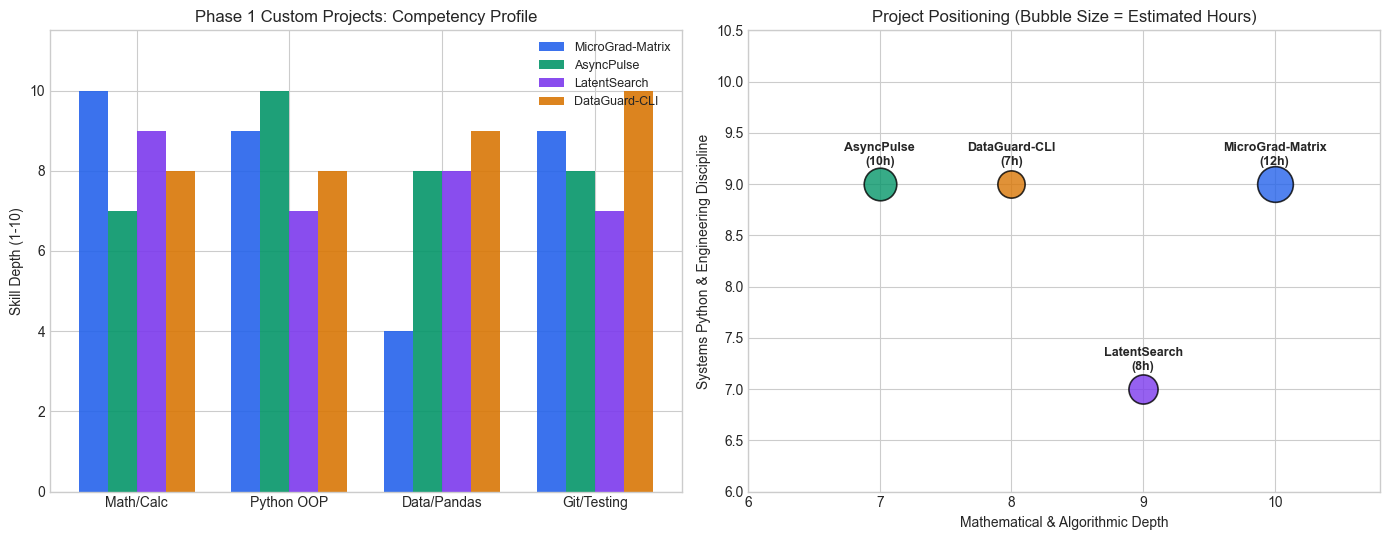

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left Panel: Grouped Skill Intensity Bars
pillars = list(catalog[0].skills.keys())
x = np.arange(len(pillars))
width = 0.19
colors = ["#2563eb", "#059669", "#7c3aed", "#d97706"]

for i, spec in enumerate(catalog):
    vals = [spec.skills[p] for p in pillars]
    axes[0].bar(x + (i - 1.5) * width, vals, width=width, label=spec.name, color=colors[i], alpha=0.9)

axes[0].set_xticks(x)
axes[0].set_xticklabels(pillars)
axes[0].set_ylim(0, 11.5)
axes[0].set_ylabel("Skill Depth (1-10)")
axes[0].set_title("Phase 1 Custom Projects: Competency Profile")
axes[0].legend(loc="upper right", fontsize=9)

# Right Panel: Effort vs Math-to-Systems Balance
math_scores = [s.skills["Math/Calc"] for s in catalog]
sys_scores = [0.5 * (s.skills["Python OOP"] + s.skills["Git/Testing"]) for s in catalog]
sizes = [s.hours * 55 for s in catalog]

for i, spec in enumerate(catalog):
    axes[1].scatter(math_scores[i], sys_scores[i], s=sizes[i], color=colors[i], alpha=0.8, edgecolors="black", linewidth=1.2)
    axes[1].annotate(f"{spec.name}\n({spec.hours}h)", (math_scores[i], sys_scores[i]),
                     textcoords="offset points", xytext=(0, 14), ha="center", fontsize=9, fontweight="bold")

axes[1].set_xlim(6.0, 10.8)
axes[1].set_ylim(6.0, 10.5)
axes[1].set_xlabel("Mathematical & Algorithmic Depth")
axes[1].set_ylabel("Systems Python & Engineering Discipline")
axes[1].set_title("Project Positioning (Bubble Size = Estimated Hours)")

plt.tight_layout()
plt.show()


## 8. Guided Customization Exercises

### Exercise 1: Extend `MatrixTensor` With Elementwise Subtraction & Mean Loss
Add a `.sub()` / `__sub__` method and `.mean()` reduction to `MatrixTensor` (or implement as a functional wrapper) so you can compute Mean Squared Error $\frac{1}{N}\|\hat{y} - y\|_2^2$ directly.


In [9]:
def mse_forward_and_backward(y_pred: MatrixTensor, y_target: np.ndarray) -> MatrixTensor:
    diff = MatrixTensor(y_pred.data - y_target, (y_pred,), "diff")

    def _diff_bw() -> None:
        y_pred.grad += diff.grad

    diff._backward = _diff_bw
    sq = diff.sum_squares()
    n = float(y_target.size)
    mse = MatrixTensor(sq.data / n, (sq,), "mean")

    def _mean_bw() -> None:
        sq.grad += mse.grad / n

    mse._backward = _mean_bw
    return mse


pred = MatrixTensor([[2.0], [4.0]])
target = np.array([[1.0], [2.0]])
loss_mse = mse_forward_and_backward(pred, target)
loss_mse.backward()
expected_grad = 2.0 * (pred.data - target) / target.size
assert np.allclose(pred.grad, expected_grad)
print(f"Exercise 1 PASSED -> MSE={float(loss_mse.data):.4f} | dMSE/dPred={pred.grad.ravel().tolist()}")


Exercise 1 PASSED -> MSE=2.5000 | dMSE/dPred=[1.0, 2.0]


## 9. Challenge Problem: Multi-Project Rubric Gate Validator

Write a gate validator verifying that any custom Phase 1 project submission satisfies all minimum thresholds (`Functionality >= 0.80`, `Testing >= 0.75`, total weighted score `>= 85.0`).


In [10]:
def validate_custom_submission(spec: CustomProjectSpec) -> bool:
    score = spec.weighted_rubric_score()
    ok = (
        spec.rubric_target["Functionality"] >= 0.80
        and spec.rubric_target["Testing"] >= 0.75
        and score >= 85.0
    )
    assert ok, f"Submission {spec.name} did not meet 85.0 release gate (got {score:.1f})"
    return ok


results = {spec.name: validate_custom_submission(spec) for spec in catalog}
print("Challenge PASSED -> Custom Project Gate Validation:", results)


Challenge PASSED -> Custom Project Gate Validation: {'MicroGrad-Matrix': True, 'AsyncPulse': True, 'LatentSearch': True, 'DataGuard-CLI': True}


## 10. Submission Checklist & Further Reading

Before moving to **Phase 2: ML Fundamentals**, verify your custom project has:
- [ ] A clean Git repository with feature branches, descriptive commits, and zero committed secrets or `.pyc` artifacts
- [ ] `README.md` with setup instructions, architecture diagram, and verified sample output
- [ ] Automated `pytest` unit tests covering math edge cases, schema contracts, and deterministic seeds
- [ ] Type hints across public functions and docstrings on core classes

**Contribute back:** Once your custom project is complete, you can showcase it in this repository using `.github/ISSUE_TEMPLATE/project_submission.md`!

**Next:** Proceed to [`Phase 2: ML Fundamentals →`](../02-ml-fundamentals/)
